In [11]:
import os, glob, json
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

root = "."

In [12]:
meta = os.path.join(root, "metadata")
print(os.listdir(meta))
classes = pd.read_csv(os.path.join(meta, "class_definitions.csv"))
classes

['class_definitions.csv', 'image_metadata.csv', 'split_assignments.csv']


,class_id,class_name,annotation_count,description
0,0,Missing Teeth,2609,Congenitally missing or previously extracted p...
1,1,Dental Crown,1984,Prosthetic dental crowns (full-coverage restor...
2,2,Root Canal,1956,Endodontically treated teeth exhibiting radiop...
3,3,Caries,1410,Carious lesions presenting as radiolucent area...
4,4,Broken Down Teeth,795,Teeth with extensive structural loss (large ca...
5,5,Wisdom Teeth,869,"Third molars (wisdom teeth), regardless of eru..."
6,6,Healthy OPG,211,Panoramic radiographs showing normal dental st...


In [15]:
splits = {}
for s in ["train", "val", "test"]:
    path = os.path.join(root, "annotations", f"instances_{s}.json")
    with open(path, encoding="utf-8") as f:
        splits[s] = json.load(f)
cats = {c["id"]: c["name"] for c in splits["train"]["categories"]}
print(cats)
for s, d in splits.items():
    print(s, ":", len(d["images"]), "images,", len(d["annotations"]), "boxes")

{0: 'class_0', 1: 'class_1', 2: 'class_2', 3: 'class_3', 4: 'class_4', 5: 'class_5', 6: 'class_6'}
train : 1676 images, 7823 boxes
val : 209 images, 923 boxes
test : 210 images, 1088 boxes


In [29]:
print(classes.columns.tolist())

id_col, name_col = classes.columns[0], classes.columns[1]
cats = dict(zip(classes[id_col], classes[name_col]))
print(cats)

['class_id', 'class_name', 'annotation_count', 'description']
{0: 'Missing Teeth', 1: 'Dental Crown', 2: 'Root Canal', 3: 'Caries', 4: 'Broken Down Teeth', 5: 'Wisdom Teeth', 6: 'Healthy OPG'}


In [43]:
rows = []
for s, d in splits.items():
    for a in d["annotations"]:
        x, y, w, h = a["bbox"]
        rows.append({"split": s, "class": cats[a["category_id"]],
                     "image_id": a["image_id"], "w": w, "h": h, "area": w * h})
df = pd.DataFrame(rows)
df.head()

,split,class,image_id,w,h,area
0,train,Wisdom Teeth,211,88.001,79.0,6952.079
1,train,Wisdom Teeth,211,71.000,66.0,4686.000
2,train,Wisdom Teeth,211,87.000,78.0,6786.000
3,train,Wisdom Teeth,211,76.000,81.0,6156.000
4,train,Caries,212,45.999,74.0,3403.926


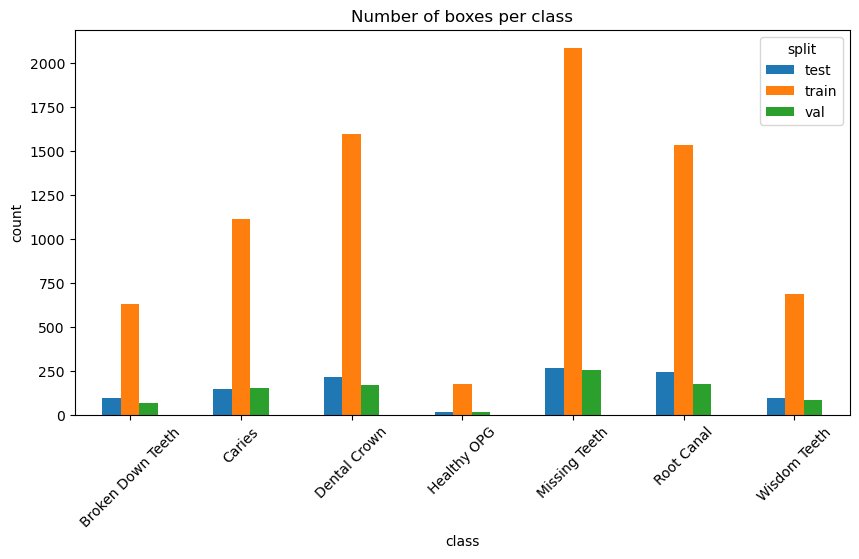

In [31]:
counts = df.groupby(["class", "split"]).size().unstack(fill_value=0)
counts.plot(kind="bar", figsize=(10, 5))
plt.title("Number of boxes per class")
plt.ylabel("count")
plt.xticks(rotation=45)
plt.show()

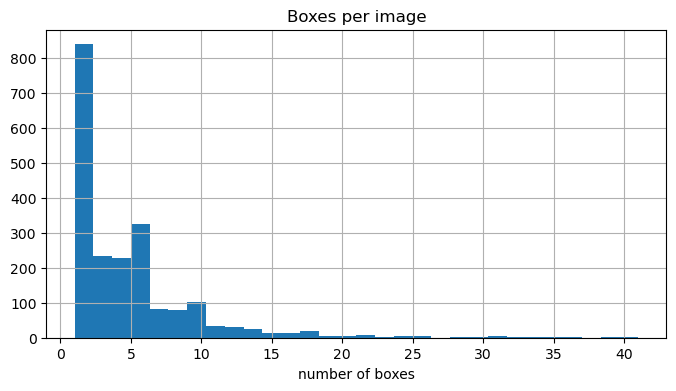

In [41]:
per_image = df.groupby(["split", "image_id"]).size()
per_image.hist(bins=30, figsize=(8, 4))
plt.title("Boxes per image")
plt.xlabel("number of boxes")
plt.show()

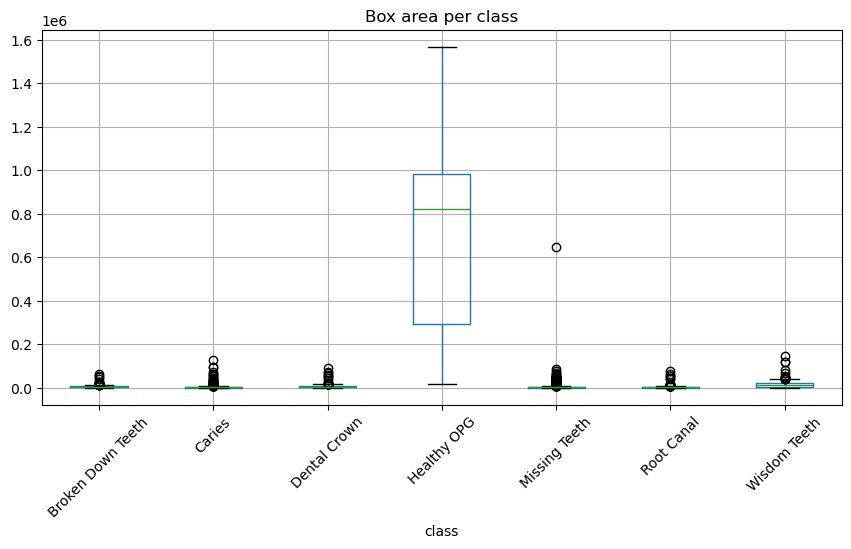

In [39]:
df.boxplot(column="area", by="class", figsize=(10, 5), rot=45)
plt.title("Box area per class")
plt.suptitle("")
plt.show()

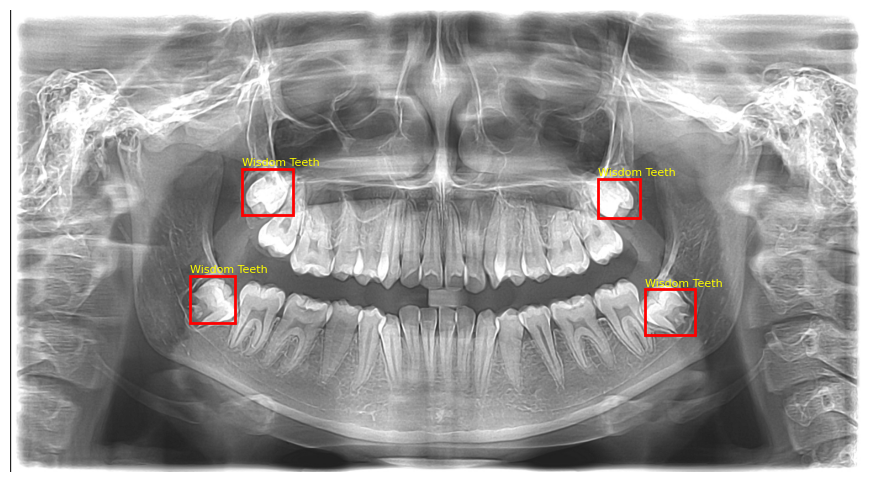

In [44]:
d = splits["train"]
img = d["images"][0]
found = glob.glob(os.path.join(root, "images", "**", os.path.basename(img["file_name"])), recursive=True)
im = Image.open(found[0])

fig, ax = plt.subplots(figsize=(12, 6))
ax.imshow(im, cmap="gray")
for a in d["annotations"]:
    if a["image_id"] == img["id"]:
        x, y, w, h = a["bbox"]
        ax.add_patch(patches.Rectangle((x, y), w, h, fill=False, color="red", linewidth=2))
        ax.text(x, y - 5, cats[a["category_id"]], color="yellow", fontsize=8)
ax.axis("off")
plt.show()

In [48]:
# Calculate annotation and image counts for each class

class_analysis = df.groupby("class").agg(
    Annotations=("image_id", "count"),
    Images=("image_id", lambda x: df.loc[x.index, ["split", "image_id"]].drop_duplicates().shape[0])
)

class_analysis = class_analysis.sort_values(
    by="Annotations", ascending=False
)

display(class_analysis)

,Annotations,Images
class,,
Missing Teeth,2609,1124
Dental Crown,1984,595
Root Canal,1956,609
Caries,1410,870
Wisdom Teeth,869,416
Broken Down Teeth,795,349
Healthy OPG,211,210


In [50]:
# Calculate class imbalance ratio

imbalance_ratio = (
    class_analysis["Annotations"].max() /
    class_analysis["Annotations"].min()
)

print(f"Class Imbalance Ratio: {imbalance_ratio:.2f}")

print(
    f"The most frequent class is: "
    f"{class_analysis['Annotations'].idxmax()}"
)

print(
    f"The least frequent class is: "
    f"{class_analysis['Annotations'].idxmin()}"
)

Class Imbalance Ratio: 12.36
The most frequent class is: Missing Teeth
The least frequent class is: Healthy OPG


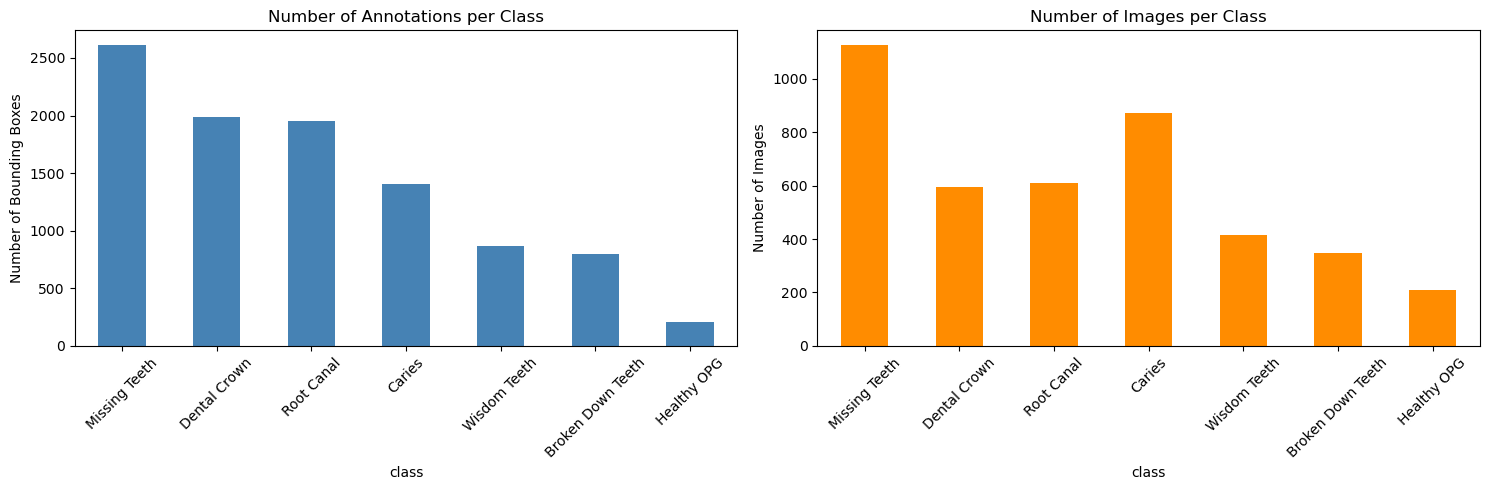

In [52]:
# Visualize class representation

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

class_analysis["Annotations"].plot(
    kind="bar", ax=axes[0], color="steelblue"
)
axes[0].set_title("Number of Annotations per Class")
axes[0].set_ylabel("Number of Bounding Boxes")
axes[0].tick_params(axis="x", rotation=45)

class_analysis["Images"].plot(
    kind="bar", ax=axes[1], color="darkorange"
)
axes[1].set_title("Number of Images per Class")
axes[1].set_ylabel("Number of Images")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [54]:
# Calculate percentage of each class

class_analysis["Percentage"] = (
    class_analysis["Annotations"] /
    class_analysis["Annotations"].sum()
) * 100

display(class_analysis.round(2))

,Annotations,Images,Percentage
class,,,
Missing Teeth,2609,1124,26.53
Dental Crown,1984,595,20.17
Root Canal,1956,609,19.89
Caries,1410,870,14.34
Wisdom Teeth,869,416,8.84
Broken Down Teeth,795,349,8.08
Healthy OPG,211,210,2.15


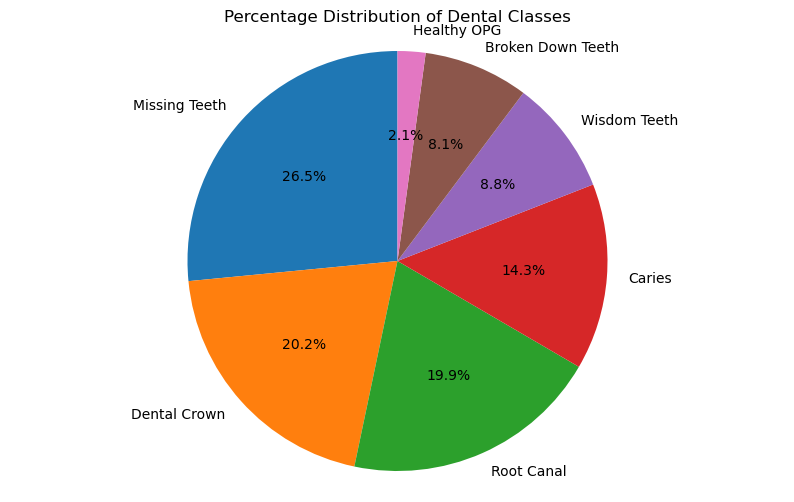

In [56]:
# Visualize percentage distribution

plt.figure(figsize=(10, 6))

plt.pie(
    class_analysis["Annotations"],
    labels=class_analysis.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Percentage Distribution of Dental Classes")
plt.axis("equal")
plt.show()

In [58]:
# Extract bounding box center coordinates

spatial_rows = []

for s, d in splits.items():

    image_lookup = {
        img["id"]: img for img in d["images"]
    }

    for a in d["annotations"]:

        x, y, w, h = a["bbox"]

        img = image_lookup[a["image_id"]]

        image_width = img["width"]
        image_height = img["height"]

        spatial_rows.append({
            "class": cats[a["category_id"]],
            "split": s,
            "x_center": (x + w / 2) / image_width,
            "y_center": (y + h / 2) / image_height
        })

spatial_df = pd.DataFrame(spatial_rows)

print("Spatial dataset shape:", spatial_df.shape)

display(spatial_df.head())

Spatial dataset shape: (9834, 4)


,class,split,x_center,y_center
0,Wisdom Teeth,train,0.302198,0.393805
1,Wisdom Teeth,train,0.716003,0.407080
2,Wisdom Teeth,train,0.775755,0.653603
3,Wisdom Teeth,train,0.237637,0.626422
4,Caries,train,0.359986,0.672207


Total Caries annotations: 1410


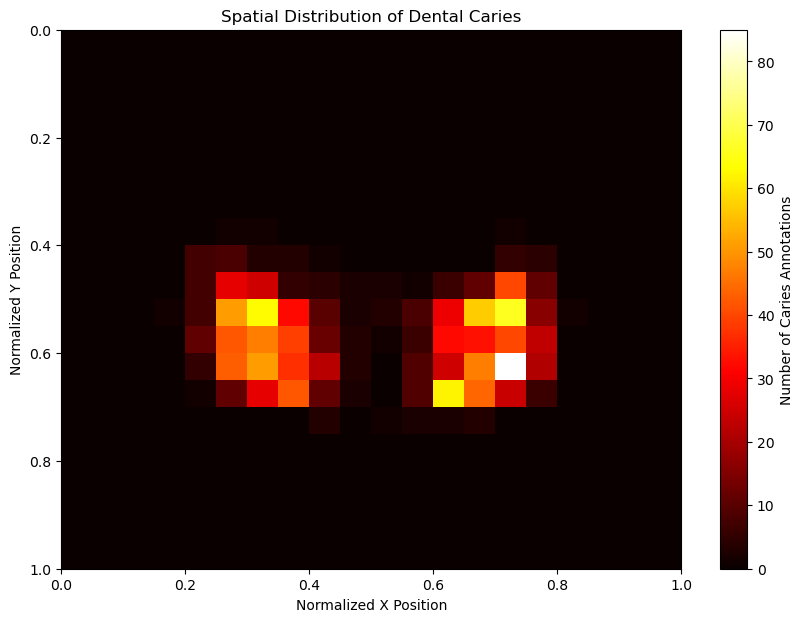

In [60]:
# Filter caries annotations

caries_df = spatial_df[
    spatial_df["class"] == "Caries"
]

print("Total Caries annotations:", len(caries_df))

plt.figure(figsize=(10, 7))

plt.hist2d(
    caries_df["x_center"],
    caries_df["y_center"],
    bins=20,
    range=[[0, 1], [0, 1]],
    cmap="hot"
)

plt.colorbar(label="Number of Caries Annotations")

plt.title("Spatial Distribution of Dental Caries")
plt.xlabel("Normalized X Position")
plt.ylabel("Normalized Y Position")

plt.gca().invert_yaxis()

plt.show()

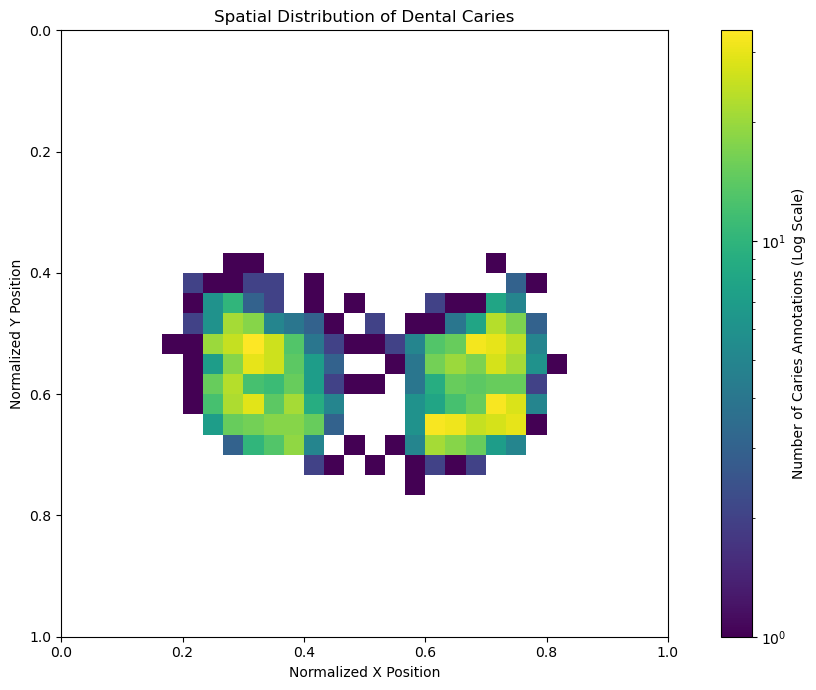

In [62]:
from matplotlib.colors import LogNorm

plt.figure(figsize=(11, 7))

plt.hist2d(
    caries_df["x_center"],
    caries_df["y_center"],
    bins=30,
    range=[[0, 1], [0, 1]],
    cmap="viridis",
    cmin=1,
    norm=LogNorm(vmin=1)
)

plt.colorbar(label="Number of Caries Annotations (Log Scale)")

plt.title("Spatial Distribution of Dental Caries")
plt.xlabel("Normalized X Position")
plt.ylabel("Normalized Y Position")

plt.gca().invert_yaxis()
plt.gca().set_aspect("equal")

plt.tight_layout()
plt.show()

C:\Users\GOD\AppData\Local\Temp\ipykernel_18288\3366098281.py:57: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


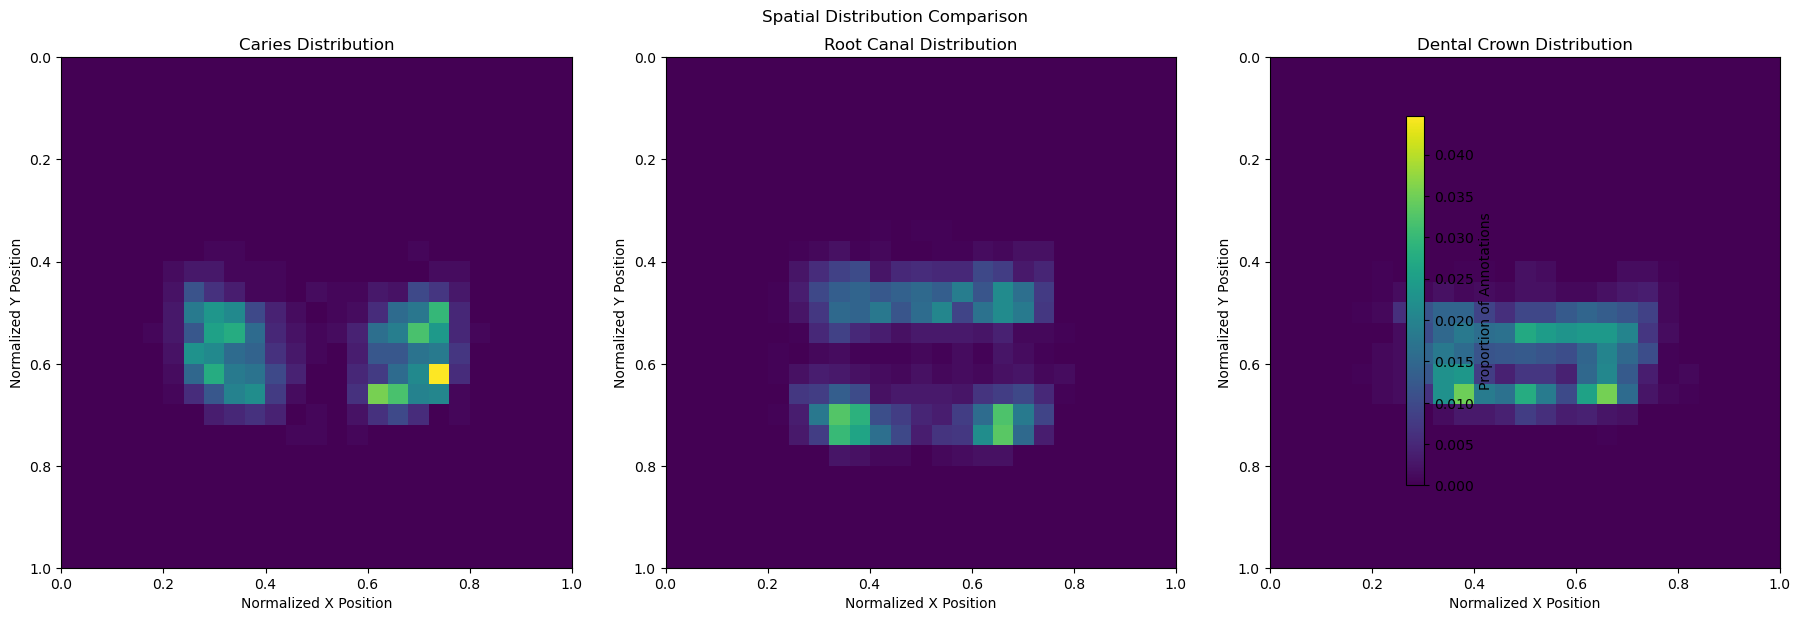

In [64]:
import numpy as np

selected_classes = [
    "Caries",
    "Root Canal",
    "Dental Crown"
]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

histograms = []

# Calculate normalized spatial histograms
for class_name in selected_classes:

    temp = spatial_df[spatial_df["class"] == class_name]

    hist, xedges, yedges = np.histogram2d(
        temp["x_center"],
        temp["y_center"],
        bins=25,
        range=[[0, 1], [0, 1]]
    )

    hist = hist / hist.sum()
    histograms.append(hist)

# Use the same color scale for all classes
vmax = max(hist.max() for hist in histograms)

for ax, class_name, hist in zip(
    axes, selected_classes, histograms
):

    im = ax.imshow(
        hist.T,
        origin="upper",
        extent=[0, 1, 1, 0],
        cmap="viridis",
        vmin=0,
        vmax=vmax,
        aspect="equal"
    )

    ax.set_title(f"{class_name} Distribution")
    ax.set_xlabel("Normalized X Position")
    ax.set_ylabel("Normalized Y Position")

fig.colorbar(
    im,
    ax=axes,
    label="Proportion of Annotations",
    shrink=0.8
)

plt.suptitle("Spatial Distribution Comparison")
plt.tight_layout()
plt.show()